In [71]:
import os
import sys
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [72]:
inputs_dir = Path("../1_inputs/")
outputs_dir = Path("../3_outputs/")

In [73]:
# import allele collection file
allele_collection_df = pd.read_csv(outputs_dir / "varchamp_seq_confirm_alleles_clinvar_gnomad.tsv", sep="\t")
allele_collection_df

,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,gnomad_af
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6_No_ClinVar,NaN
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6_No_ClinVar,NaN
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,-,SCV000232587|SCV000321701|SCV000893215|SCV0009...,-,-,887G>A,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,0.000078
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,-,SCV000111209|SCV000491300|SCV000692643|SCV0006...,-,-,1448T>C,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,0.000084
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,-,SCV000697586|SCV001422687|SCV001713036|SCV0020...,-,-,259C>T,Arg87Trp,NM_000157.4,2.0,1_Pathogenic,0.000012
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,-,SCV000513395,-,-,197T>A,Leu66His,NM_018684.4,NaN,1_Pathogenic,NaN
9149,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,-,SCV000589376|SCV002011544|SCV002512603|SCV0025...,-,-,593G>A,Arg198Gln,NM_018684.4,2.0,1_Pathogenic,NaN
9150,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,-,SCV000513398,-,-,53G>A,Arg18Lys,NM_018684.4,NaN,1_Pathogenic,NaN
9151,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,-,SCV001583928|SCV002074112|SCV002655406,-,-,637C>T,Arg213Trp,NM_018684.4,2.0,1_Pathogenic,NaN


In [74]:
allele_collection_df.collection.unique()

array(['RC4', 'CEGS2', 'Edgotyping3', nan], dtype=object)

In [75]:
# inspect columns

allele_collection_df.columns

Index(['symbol', 'ensembl_gene_id', 'orf_id', 'mut_id', 'ccsb_mutation_id',
       'ccsb_allele_id', 'spdi', 'nt_change', 'aa_change', 'collection',
       'entry_plate_orig', 'entry_well_orig', 'entry_plate_conso',
       'entry_well_conso', 'entry_seq_pool', 'db_plate', 'db_well',
       'n2h_plate', 'n2h_well', 'dualip_plate', 'dualip_well',
       'mislocalization_plate', 'mislocalization_well', 'entry_sequenced',
       'entry_sequence_confirmation_class', 'db_sequenced',
       'db_sequence_confirmation_class', 'n2h_sequenced',
       'n2h_sequence_confirmation_class',
       'n2h_ref_sequence_confirmation_class', 'dualip_sequenced',
       'dualip_sequence_confirmation_class',
       'dualip_ref_sequence_confirmation_class', 'mislocalization_sequenced',
       'mislocalization_sequence_confirmation_class',
       'mislocalization_ref_sequence_confirmation_class', 'gene_variant',
       'chr_num', 'nuc_loc', 'ref_allele', 'alt_allele', 'Chrom',
       'entry_seq_final', 'db_seq_f

In [76]:
# explore PhenotypeIDS
allele_collection_df['PhenotypeIDS'].value_counts()

PhenotypeIDS
MedGen:CN517202                                                                                                                                                                              261
MedGen:C3661900                                                                                                                                                                              181
-                                                                                                                                                                                             97
MONDO:MONDO:0009258,MedGen:C0268151,OMIM:230400,Orphanet:352,Orphanet:79239                                                                                                                   41
MedGen:CN169374                                                                                                                                                                               41
                      

In [77]:
# extract omim data from PhenotypeIDS and store in into OMIM_IDs column
allele_collection_df['OMIM_IDs'] = allele_collection_df['PhenotypeIDS'].str.extractall(r'OMIM:(\d+)')[0].groupby(level=0).apply(list)
allele_collection_df

,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,gnomad_af,OMIM_IDs
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6_No_ClinVar,NaN,NaN
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6_No_ClinVar,NaN,NaN
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,SCV000232587|SCV000321701|SCV000893215|SCV0009...,-,-,887G>A,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,0.000078,"[608013, 230800, 230900, 231000, 231005, 16860..."
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,SCV000111209|SCV000491300|SCV000692643|SCV0006...,-,-,1448T>C,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,0.000084,"[230900, 230800, 231000, 168600, 608013, 23080..."
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,SCV000697586|SCV001422687|SCV001713036|SCV0020...,-,-,259C>T,Arg87Trp,NM_000157.4,2.0,1_Pathogenic,0.000012,"[230800, 127750, 168600]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,SCV000513395,-,-,197T>A,Leu66His,NM_018684.4,NaN,1_Pathogenic,NaN,[314580]
9149,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,SCV000589376|SCV002011544|SCV002512603|SCV0025...,-,-,593G>A,Arg198Gln,NM_018684.4,2.0,1_Pathogenic,NaN,"[314580, 301041]"
9150,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,SCV000513398,-,-,53G>A,Arg18Lys,NM_018684.4,NaN,1_Pathogenic,NaN,[314580]
9151,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,SCV001583928|SCV002074112|SCV002655406,-,-,637C>T,Arg213Trp,NM_018684.4,2.0,1_Pathogenic,NaN,[314580]


In [78]:
allele_collection_gene_list = allele_collection_df['symbol'].dropna().unique().tolist()
allele_collection_gene_list

['GBA1',
 'NHERF1',
 'MRPL3',
 'PFN1',
 'PLEKHG5',
 'CANT1',
 'MYD88',
 'EZH2',
 'PTS',
 'ACTA2',
 'FOXA3',
 'RFX5',
 'HYLS1',
 'ALDOA',
 'CTH',
 'PEPD',
 'MVK',
 'MATR3',
 'ABHD5',
 'RAB18',
 'GALT',
 'VPS33B',
 'TYROBP',
 'DDHD2',
 'OXCT1',
 'CBS',
 'SERPING1',
 'STAR',
 'CLU',
 'CYC1',
 'DPM2',
 'BPGM',
 'SEMA4A',
 'GJB2',
 'CRADD',
 'FA2H',
 'ETFA',
 'CD40',
 'SPINT2',
 'SERPINA1',
 'AGA',
 'PRNP',
 'NTF4',
 'NRL',
 'CES1',
 'PTGS2',
 'HAX1',
 'RAF1',
 'MSX2',
 'TFPI',
 'RPIA',
 'CAPN5',
 'CYB5A',
 'A4GALT',
 'SCO1',
 'BCHE',
 'PLOD1',
 'SLC25A38',
 'PCCB',
 'ASAH1',
 'RXYLT1',
 'LBR',
 'ARL11',
 'MAT1A',
 'PCCA',
 'TSEN34',
 'MMADHC',
 'SULT1A1',
 'OAT',
 'NDUFA10',
 'LCK',
 'PSAT1',
 'TPP1',
 'YARS1',
 'CDK5R1',
 'BMP4',
 'PRKAG2',
 'SMN2',
 'LFNG',
 'ACADVL',
 'ETNPPL',
 'GJA1',
 'GAD1',
 'PDYN',
 'AQP1',
 'KCNJ10',
 'BBS10',
 'KLHL3',
 'CRYM',
 'PIP4K2A',
 'LGI1',
 'OMG',
 'TSPAN7',
 'SLC40A1',
 'PAK5',
 'SGCE',
 'CD46',
 'GPAM',
 'CALR3',
 'HLA-G',
 'LARS2',
 'USP44',
 'TMEM67

In [79]:
# Load OMIM data

omim_df = pd.read_csv(inputs_dir / 'mimTitles.txt', sep="\t", skiprows=2)
omim_df.dropna(subset=['MIM Number'], inplace=True)
omim_df['MIM Number'] = omim_df['MIM Number'].astype(int)
omim_df['disease_name'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[0])
omim_df['Symbol'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[-1] if ';' in x else None)
omim_df.drop(columns=['Preferred Title; symbol'], inplace=True)
omim_df

,# Prefix,MIM Number,Alternative Title(s); symbol(s),Included Title(s); symbols,disease_name,Symbol
0,NaN,100050,NaN,NaN,"AARSKOG SYNDROME, AUTOSOMAL DOMINANT",None
1,Percent,100070,"ANEURYSM, ABDOMINAL AORTIC; AAA;; ABDOMINAL AO...",NaN,"AORTIC ANEURYSM, FAMILIAL ABDOMINAL, 1",AAA1
2,Number Sign,100100,"ABDOMINAL MUSCLES, ABSENCE OF, WITH URINARY TR...",NaN,PRUNE BELLY SYNDROME,PBS
3,NaN,100200,NaN,NaN,ABDUCENS PALSY,None
4,Number Sign,100300,"AOS;; ABSENCE DEFECT OF LIMBS, SCALP, AND SKUL...","APLASIA CUTIS CONGENITA, CONGENITAL HEART DEFE...",ADAMS-OLIVER SYNDROME 1,AOS1
...,...,...,...,...,...,...
29097,Asterisk,621148,NaN,NaN,CHROMOSOME 16 OPEN READING FRAME 89,C16ORF89
29098,Asterisk,621149,LEG1,NaN,CHROMOSOME 6 OPEN READING FRAME 58,C6ORF58
29099,Number Sign,621150,NaN,NaN,NEURODEVELOPMENTAL DISORDER WITH THIN CORPUS C...,NEDTCHAL
29100,Asterisk,621151,KYNURENINE FORMAMIDASE; KF; KFA,NaN,ARYLFORMAMIDASE,AFMID


In [80]:
# omim_dict = omim_df.set_index('MIM Number')['disease_name'].to_dict()
# omim_dict

In [81]:
# import rare disease module file
# from https://www.nature.com/articles/s41467-021-26674-1
# supplementary data 5

rd_df = pd.read_csv(inputs_dir / 'rare_disease_modules.txt', sep='\t')
rd_df

,name,all_genes
0,Rare genetic vascular disease,SLC2A10;MYH11;COL3A1;COL5A1;TGFBR2;FBN1;SMAD3;...
1,Rare genetic systemic or rheumatologic disease,PSMB8;SAMHD1;RNASEH2A;RNASEH2B;RNASEH2C;ADAR;T...
2,Rare genetic eye disease,NF1;RB1;MYCN;PITX2;SCO2;P3H2;LRPAP1;KERA;PIK3R...
3,Rare genetic gynecological and obstetrical dis...,H6PD;HSD11B1;ESR1;GNAS;KISS1R;MKRN3;DLK1;CYP19...
4,Rare genetic immune disease,WAS;WIPF1;FOXN1;DKC1;TERT;TERC;TINF2;NOP10;NHP...
5,Rare genetic cardiac disease,TTN;PKP2;RYR2;TGFB3;DSC2;DSG2;DSP;JUP;LDB3;LMN...
6,Rare genetic renal disease,HBB;HBA2;HBA1;RAD51;MAD2L2;BRCA1;XRCC2;RFWD3;B...
7,Rare genetic developmental defect during embry...,ATM;KITLG;SNAI2;SOX10;MITF;EDNRB;PAX3;ACVRL1;S...
8,Rare genetic bone disease,AGA;SUMF1;MANBA;FUCA1;GNPTAB;GUSB;CTSA;ARSB;ID...
9,Rare genetic odontologic disease,GINGF2;SOS1;REST;BRF1;PTH1R;FAM83H;SLC24A4;ITG...


In [82]:
rd_dict = {rd:gene_list.split(';') for rd, gene_list in zip(rd_df['name'], rd_df['all_genes'])}
rd_dict

{'Rare genetic vascular disease': ['SLC2A10',
  'MYH11',
  'COL3A1',
  'COL5A1',
  'TGFBR2',
  'FBN1',
  'SMAD3',
  'NKX2-5',
  'GATA5',
  'NOTCH1',
  'SMAD6',
  'ACTA2',
  'TGFBR1',
  'FOXE3',
  'LOX',
  'MAT2A',
  'ELN',
  'TGFB3',
  'MYLK',
  'PRKG1',
  'MFAP5',
  'TGFB2'],
 'Rare genetic systemic or rheumatologic disease': ['PSMB8',
  'SAMHD1',
  'RNASEH2A',
  'RNASEH2B',
  'RNASEH2C',
  'ADAR',
  'TREX1',
  'IFIH1',
  'ACP5',
  'ISG15',
  'C1QA',
  'C4A',
  'DNASE1L3',
  'PRKCD',
  'DNASE1',
  'ADA2',
  'TMEM173',
  'USP18',
  'DDX58',
  'POLA1',
  'TTC37',
  'SKIV2L',
  'APOA2',
  'APP',
  'B2M',
  'GSN',
  'ITM2B',
  'FGA',
  'APOA1',
  'LYZ',
  'CST3',
  'TTR',
  'RBCK1',
  'RNF31',
  'PLCG2',
  'MEFV',
  'NLRP12',
  'NLRC4',
  'OTULIN',
  'TNFRSF1A',
  'MVK',
  'NLRP3',
  'SLC39A13',
  'P4HA1',
  'CHST14',
  'DSE',
  'COL1A1',
  'COL1A2',
  'FLNA',
  'TNXB',
  'PLOD1',
  'COL3A1',
  'COL5A1',
  'ADAMTS2',
  'FKBP14',
  'C1S',
  'C1R',
  'B4GALT7',
  'B3GALT6',
  'ZNF469',
  'P

In [83]:
# create a dict for each disease module with the genes found in our allele collection
disease_module_dict = {rd: [gene for gene in gene_list if gene in allele_collection_gene_list] for rd, gene_list in rd_dict.items()}
disease_module_dict

{'Rare genetic vascular disease': ['SLC2A10',
  'TGFBR2',
  'SMAD3',
  'NKX2-5',
  'SMAD6',
  'ACTA2',
  'TGFBR1'],
 'Rare genetic systemic or rheumatologic disease': ['SAMHD1',
  'RNASEH2C',
  'TREX1',
  'C1QA',
  'B2M',
  'FGA',
  'APOA1',
  'LYZ',
  'CST3',
  'TTR',
  'TNFRSF1A',
  'MVK',
  'SLC39A13',
  'CHST14',
  'PLOD1',
  'C1S',
  'B4GALT7',
  'TGFBR2',
  'SMAD3',
  'TGFBR1',
  'ACTA2'],
 'Rare genetic eye disease': ['MYCN',
  'PITX2',
  'SCO2',
  'P3H2',
  'KERA',
  'PIK3R1',
  'NMNAT1',
  'RDH12',
  'RPE65',
  'CEP290',
  'AIPL1',
  'TULP1',
  'CRX',
  'IMPDH1',
  'KCNJ13',
  'LRAT',
  'RPGR',
  'CNGA3',
  'ATF6',
  'CYBB',
  'NCF1',
  'NCF2',
  'PHC1',
  'GFAP',
  'PNKP',
  'FXN',
  'ATM',
  'CHN1',
  'MAFB',
  'APTX',
  'PLP1',
  'SETX',
  'GLB1',
  'TMEM216',
  'TMEM138',
  'TMEM67',
  'ARL13B',
  'INPP5E',
  'CEP41',
  'HYLS1',
  'KIF7',
  'NPC2',
  'MAPT',
  'NDUFA13',
  'SDHA',
  'SLC19A3',
  'SURF1',
  'COX15',
  'NDUFS1',
  'NDUFS3',
  'NDUFS7',
  'NDUFV1',
  'PDHA1',

In [84]:
# to table with gene count

dict_for_table = {rd:gene_joined for rd, gene_list in disease_module_dict.items() for gene_joined in [';'.join(gene_list)]}
disease_module_df = pd.DataFrame(list(dict_for_table.items()), columns=['disease_module', 'genes'])
disease_module_df.columns = ['disease_module', 'genes']
disease_module_df['gene_count'] = disease_module_df['genes'].str.split(';').str.len()
disease_module_df

,disease_module,genes,gene_count
0,Rare genetic vascular disease,SLC2A10;TGFBR2;SMAD3;NKX2-5;SMAD6;ACTA2;TGFBR1,7
1,Rare genetic systemic or rheumatologic disease,SAMHD1;RNASEH2C;TREX1;C1QA;B2M;FGA;APOA1;LYZ;C...,21
2,Rare genetic eye disease,MYCN;PITX2;SCO2;P3H2;KERA;PIK3R1;NMNAT1;RDH12;...,367
3,Rare genetic gynecological and obstetrical dis...,HSD11B1;ESR1;GNAS;CYP19A1;SEMA3E;HBB;RBM28;BBS...,67
4,Rare genetic immune disease,DKC1;TINF2;NOP10;NHP2;WRAP53;CCBE1;STIM1;IKBKG...,107
5,Rare genetic cardiac disease,PKP2;JUP;LDB3;LMNA;TMEM43;CTNNA3;ACTC1;TNNT2;T...,106
6,Rare genetic renal disease,HBB;HBA2;HBA1;BRCA1;XRCC2;BRIP1;FANCC;FANCD2;F...,155
7,Rare genetic developmental defect during embry...,ATM;KITLG;SOX10;MITF;EDNRB;PAX3;ACVRL1;SMAD4;G...,524
8,Rare genetic bone disease,AGA;FUCA1;GNPTAB;GUSB;CTSA;IDS;GALNS;GLB1;GNPT...,167
9,Rare genetic odontologic disease,PTH1R;GPR68;AXIN2;EDA;FGFR1;WNT10A;MSX1;PAX9;S...,12


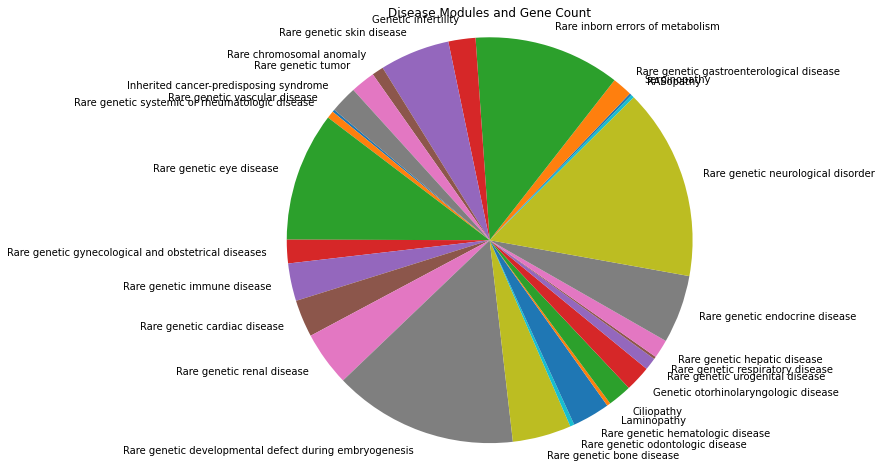

In [85]:
plt.figure(figsize=(8, 8))
plt.pie(disease_module_df['gene_count'], labels=disease_module_df['disease_module'], startangle=140)
plt.title('Disease Modules and Gene Count')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

In [86]:
disease_module_df.to_csv(outputs_dir / 'disease_modules_to_genes.tsv', sep='\t', index=False)

In [87]:
# Some genes are associated with more than 1 module
# table to plot the number of genes associated with 1 module, 2 modules, 3 modules, etc.

gene_module_dict = {}

for _, row in disease_module_df.iterrows():
    gene_list = row['genes'].split(';')
    for gene in gene_list:
        if gene in gene_module_dict:
            gene_module_dict[gene] += 1
        else:
            gene_module_dict[gene] = 1
            
gene_module_df = pd.DataFrame(list(gene_module_dict.items()), columns=['gene', 'module_count'])
gene_module_df

,gene,module_count
0,SLC2A10,3
1,TGFBR2,7
2,SMAD3,2
3,NKX2-5,6
4,SMAD6,2
...,...,...
1268,HABP2,1
1269,MSR1,1
1270,PMS1,2
1271,MLH3,2


In [88]:
module_count = gene_module_df.module_count.value_counts().sort_index()
module_counts_df = pd.DataFrame(module_count)
module_counts_df.to_csv(outputs_dir / 'module_counts.tsv', sep='\t', index=False)

<Axes: xlabel='module_count'>

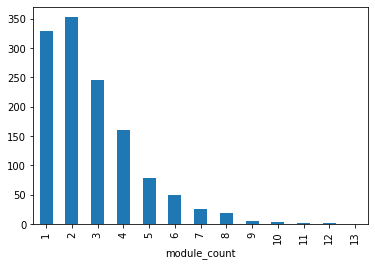

In [89]:
gene_module_df.module_count.value_counts().sort_index().plot(kind='bar')

## Inheritance patterns

In [90]:
omim_ids = set()

for omim_list in allele_collection_df['OMIM_IDs'].dropna():
    omim_ids.update(omim_list)

In [91]:
api_key = open(inputs_dir / 'OMIM_api_key.txt', 'r').read() # create the file with your own api key

In [92]:
import itertools, time, re, requests
from typing import Iterable, List, Optional, Union
from urllib3.util.retry import Retry
from requests.adapters import HTTPAdapter

# ---------- one session, automatic retries ----------
def _session(max_retries=5, backoff=0.5):
    r = Retry(total=max_retries,
              backoff_factor=backoff,
              status_forcelist=[429, 500, 502, 503, 504],
              allowed_methods=["GET"])
    s = requests.Session()
    s.mount("https://", HTTPAdapter(max_retries=r))
    s.headers["User-Agent"] = "omim-inheritance-fetch/0.1"
    return s

S = _session()

_split = re.compile(r"[;,/]")

def _inheritance(entry: dict) -> List[str]:
    pml = (entry.get("phenotypeMapList") or
           entry.get("geneMap", {}).get("phenotypeMapList"))
    raw = (
        [pm["phenotypeMap"]["phenotypeInheritance"]
         for pm in pml or []
         if pm.get("phenotypeMap", {}).get("phenotypeInheritance")]
        or [entry.get("clinicalSynopsis", {}).get("inheritance")]  # fallback
    )
    return sorted({p.strip() for x in raw for p in _split.split(x or "") if p.strip()})

def fetch_many(ids: Iterable[Union[int, str]],
               api_key: str,
               *,
               chunk=20,
               pause=0.3) -> dict[str, Optional[List[str]]]:
    out = {}
    for grp in itertools.zip_longest(*[iter(ids)]*chunk):
        batch = [str(i) for i in grp if i is not None]
        url = ("https://api.omim.org/api/entry"
               f"?mimNumber={','.join(batch)}&include=geneMap,clinicalSynopsis"
               f"&format=json&apiKey={api_key}")
        try:
            r = S.get(url, timeout=15)
            r.raise_for_status()
            for rec in r.json().get("omim", {}).get("entryList", []):
                e = rec.get("entry", {})
                out[str(e.get("mimNumber"))] = _inheritance(e) or None
        except requests.RequestException as exc:
            for bid in batch:
                out[bid] = None                # mark failed IDs
            print(f"batch {batch} failed → {exc}")
        time.sleep(pause)
    return out


In [93]:
import json
# Check if inheritance file already exists
inheritance_file_pattern = "omim_inheritance_*.json"
existing_files = list(outputs_dir.glob(inheritance_file_pattern))

if existing_files:
    print(f"Found existing inheritance file: {existing_files[0]}")
    print("Loading inheritance data from file...")
    # Load existing inheritance data from JSON
    with open(existing_files[0], 'r') as f:
        inheritance_map = json.load(f)
    print(f"Loaded {len(inheritance_map)} inheritance mappings")
else:
    print("No existing inheritance file found. Fetching from OMIM API...")
    inheritance_map = fetch_many(omim_ids, api_key)

Found existing inheritance file: ../3_outputs/omim_inheritance_20250610_144345.json
Loading inheritance data from file...
Loaded 1954 inheritance mappings


In [94]:
cleaned_inheritance_map = inheritance_map

In [95]:
# to run the API call standalone

# inheritance_map = fetch_many(omim_ids, api_key)

In [96]:
import re
from typing import Dict

# pattern that removes everything starting with the first " {" (brace & space)
_CROP_BRACES = re.compile(r"\s*\{.*")
# token must contain a-z to be meaningful
_HAS_LOWER   = re.compile(r"[a-z]")

def refine_inheritance_map(
    raw: Dict[str, Optional[List[str]]]
) -> Dict[str, Optional[List[str]]]:
    """
    Strip ontology codes and keep only human-readable inheritance terms.
    """
    clean: Dict[str, Optional[List[str]]] = {}
    for omim, items in raw.items():
        if not items:
            clean[omim] = None
            continue

        terms = {
            _CROP_BRACES.sub("", s).strip()      # cut trailing codes
            for s in items if s
        }
        terms = {
            t for t in terms
            if t and _HAS_LOWER.search(t)        # keep if it has a lowercase letter
        }

        clean[omim] = sorted(terms) or None
    return clean



In [97]:
# cleaned_inheritance_map = refine_inheritance_map(inheritance_map)
# cleaned_inheritance_map

In [98]:
from datetime import datetime
from zoneinfo import ZoneInfo          # std-lib on Python ≥ 3.9
from pathlib import Path
import json

def save_inheritance_tsv(
    inheritance_map: Dict[str, Optional[List[str]]],
    out_dir: str = "."
) -> str:
    """
    Write `inheritance_map` to a JSON named
    omim_inheritance_YYYYMMDD_HHMMSS.json in `out_dir`.

    Parameters
    ----------
    inheritance_map : dict
        {omim_id: ["Autosomal dominant", ...] or None}
    out_dir : str
        Target directory (default = current).

    Returns
    -------
    str
        Absolute path to the file that was written.
    """
    ts = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S")
    path = Path(out_dir, f"omim_inheritance_{ts}.json").resolve()

    with open(path, 'w') as json_file:
        json.dump(inheritance_map, json_file, indent=4)

    return str(path)


In [99]:
# # Run to save file if pulled and updated from OMIM API

# file_written = save_inheritance_tsv(cleaned_inheritance_map, out_dir=outputs_dir)
# print("Saved to", file_written)


In [100]:
allele_collection_df

,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,gnomad_af,OMIM_IDs
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6_No_ClinVar,NaN,NaN
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6_No_ClinVar,NaN,NaN
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,SCV000232587|SCV000321701|SCV000893215|SCV0009...,-,-,887G>A,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,0.000078,"[608013, 230800, 230900, 231000, 231005, 16860..."
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,SCV000111209|SCV000491300|SCV000692643|SCV0006...,-,-,1448T>C,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,0.000084,"[230900, 230800, 231000, 168600, 608013, 23080..."
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,SCV000697586|SCV001422687|SCV001713036|SCV0020...,-,-,259C>T,Arg87Trp,NM_000157.4,2.0,1_Pathogenic,0.000012,"[230800, 127750, 168600]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,SCV000513395,-,-,197T>A,Leu66His,NM_018684.4,NaN,1_Pathogenic,NaN,[314580]
9149,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,SCV000589376|SCV002011544|SCV002512603|SCV0025...,-,-,593G>A,Arg198Gln,NM_018684.4,2.0,1_Pathogenic,NaN,"[314580, 301041]"
9150,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,SCV000513398,-,-,53G>A,Arg18Lys,NM_018684.4,NaN,1_Pathogenic,NaN,[314580]
9151,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,SCV001583928|SCV002074112|SCV002655406,-,-,637C>T,Arg213Trp,NM_018684.4,2.0,1_Pathogenic,NaN,[314580]


In [101]:
# # George's OMIM table
# omim_inheritance_df = pd.read_csv(f'/Users/user_42/Partners HealthCare Dropbox/Maxime Tixhon/edgotyping_dropbox/large_data_files/clinical_data/inheritance/omim_id_to_inheritance_best.tsv',sep='\t')
# omim_inheritance_d = dict(zip(omim_inheritance_df.omim_id.astype(str), omim_inheritance_df.inheritance_simple))
# omim_inheritance_d

In [102]:
for i, row in allele_collection_df.iterrows():
    if row.OMIM_IDs == row.OMIM_IDs:
        inheritances = set()
        g_inheritances = set()
        for omim_id in row.OMIM_IDs:
            inheritance = cleaned_inheritance_map.get(omim_id, None)
            # g_inheritance = omim_inheritance_d.get(omim_id, None)
            # if g_inheritance is not None:
                # g_inheritances.add(g_inheritance)
            if inheritance is not None:
                for inh in inheritance:
                    inheritances.add(inh)
        allele_collection_df.at[i, "OMIM_API"] = ", ".join(inheritances)
        # allele_collection_df.at[i, "OMIM_George"] = ", ".join(g_inheritances)
    else:
        allele_collection_df.at[i, "OMIM_API"] = None
        # allele_collection_df.at[i, "OMIM_George"] = None

In [103]:
na_count = 0
single_count = 0
multiple_count = 0

for i, row in allele_collection_df.iterrows():
    if row.OMIM_API == row.OMIM_API and row.OMIM_API is not None:
        if ',' in row.OMIM_API or ';' in row.OMIM_API:
            multiple_count += 1
            allele_collection_df.at[i, 'multiple_inheritance'] = True
        else:
            single_count += 1
    else:
        na_count += 1
        
print(f"NA count: {na_count}")
print(f"Single count: {single_count}")
print(f"Multiple count: {multiple_count}")
print(f'total: {na_count + single_count + multiple_count}')

NA count: 2270
Single count: 5790
Multiple count: 1093
total: 9153


In [104]:
allele_collection_df[(allele_collection_df.OMIM_API == allele_collection_df.OMIM_API) & (allele_collection_df.multiple_inheritance != allele_collection_df.multiple_inheritance)].OMIM_API.value_counts()

OMIM_API
Autosomal recessive    3006
Autosomal dominant     1979
X-linked recessive      404
                        251
X-linked dominant        73
X-linked                 64
Y-linked                  6
Multifactorial            3
Digenic recessive         2
Somatic mutation          2
Name: count, dtype: int64

In [105]:
from Bio.PDB.Polypeptide import three_to_one
import re

def three_to_short(hgvs: str) -> str:
    """
    Convert “Val54Leu” → “V54L”, etc.
    Raises ValueError if it can’t parse or the code isn’t recognized.
    """
    m = re.match(r'^([A-Za-z]{3})(\d+)([A-Za-z]{3})$', hgvs)
    if not m:
        raise ValueError(f"Can't parse '{hgvs}'; expected format XxxNNNYYY")
    aa_from, pos, aa_to = m.groups()
    try:
        one_from = three_to_one(aa_from.upper())
        one_to   = three_to_one(aa_to.upper())
    except KeyError:
        raise ValueError(f"Unrecognized three‐letter code in '{hgvs}'")

    return f"{one_from}{pos}{one_to}"


allele_collection_df['aa_change_1_letter'] = [three_to_short(x) for x in allele_collection_df['aa_change']]
allele_collection_df

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/Bio/PDB/Polypeptide.py:144: BiopythonDeprecationWarning: 'three_to_one' will be deprecated in a future release of Biopython in favor of 'Bio.PDB.Polypeptide.protein_letters_3to1'.
  warnings.warn(


,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,gnomad_af,OMIM_IDs,OMIM_API,multiple_inheritance,aa_change_1_letter
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,6_No_ClinVar,NaN,NaN,None,NaN,V54L
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,6_No_ClinVar,NaN,NaN,None,NaN,L224F
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,887G>A,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,0.000078,"[608013, 230800, 230900, 231000, 231005, 16860...","Autosomal dominant, Multifactorial, Autosomal ...",True,R296Q
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,1448T>C,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,0.000084,"[230900, 230800, 231000, 168600, 608013, 23080...","Autosomal dominant, Multifactorial, Autosomal ...",True,L483P
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,259C>T,Arg87Trp,NM_000157.4,2.0,1_Pathogenic,0.000012,"[230800, 127750, 168600]","Autosomal dominant, Multifactorial, Autosomal ...",True,R87W
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,197T>A,Leu66His,NM_018684.4,NaN,1_Pathogenic,NaN,[314580],X-linked recessive,NaN,L66H
9149,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,593G>A,Arg198Gln,NM_018684.4,2.0,1_Pathogenic,NaN,"[314580, 301041]",X-linked recessive,NaN,R198Q
9150,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,53G>A,Arg18Lys,NM_018684.4,NaN,1_Pathogenic,NaN,[314580],X-linked recessive,NaN,R18K
9151,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,637C>T,Arg213Trp,NM_018684.4,2.0,1_Pathogenic,NaN,[314580],X-linked recessive,NaN,R213W


In [106]:
allele_collection_df['gene_var'] = allele_collection_df['symbol'] + ' ' + allele_collection_df['aa_change_1_letter']
allele_collection_df

,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,gnomad_af,OMIM_IDs,OMIM_API,multiple_inheritance,aa_change_1_letter,gene_var
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,6_No_ClinVar,NaN,NaN,None,NaN,V54L,GBA1 V54L
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,6_No_ClinVar,NaN,NaN,None,NaN,L224F,GBA1 L224F
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,0.000078,"[608013, 230800, 230900, 231000, 231005, 16860...","Autosomal dominant, Multifactorial, Autosomal ...",True,R296Q,GBA1 R296Q
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,0.000084,"[230900, 230800, 231000, 168600, 608013, 23080...","Autosomal dominant, Multifactorial, Autosomal ...",True,L483P,GBA1 L483P
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,Arg87Trp,NM_000157.4,2.0,1_Pathogenic,0.000012,"[230800, 127750, 168600]","Autosomal dominant, Multifactorial, Autosomal ...",True,R87W,GBA1 R87W
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,Leu66His,NM_018684.4,NaN,1_Pathogenic,NaN,[314580],X-linked recessive,NaN,L66H,ZC4H2 L66H
9149,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,Arg198Gln,NM_018684.4,2.0,1_Pathogenic,NaN,"[314580, 301041]",X-linked recessive,NaN,R198Q,ZC4H2 R198Q
9150,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,Arg18Lys,NM_018684.4,NaN,1_Pathogenic,NaN,[314580],X-linked recessive,NaN,R18K,ZC4H2 R18K
9151,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,Arg213Trp,NM_018684.4,2.0,1_Pathogenic,NaN,[314580],X-linked recessive,NaN,R213W,ZC4H2 R213W


In [107]:
multiple_inh = allele_collection_df[allele_collection_df.multiple_inheritance == True]

In [108]:
lacoste_df = pd.read_excel(f'{inputs_dir}/lacoste_supp.xlsx', sheet_name='Variant annotation')
lacoste_df

,Gene,Variant,Variant (alternative),Collection,Phenotype annotation,dbSNP_ID,Uniprot,Mislocalized,Mislocalization phenotype,Impact score,AlphaMissense score,AlphaMissense class,GnomAD VEP frequency,Inheritance,ClinVar class,PPI phenotype,PTM residue,PTM type,Disulfide bond,HeLa expression (TPM)
0,LDHA,LDHA K222E,NaN,hmORFeome 1.1,Lactate dehydrogenase deficiency,NaN,P00338,0.0,NaN,NaN,0.0797,benign,0.000004,autosomal recessive,No data,NaN,PTM,"ubiquitination,acetylation",NaN,476.6
1,PTEN,PTEN K6N,NaN,Target Accelerator Pan-Cancer Mutant Collection,NaN,NaN,P60484,0.0,NaN,0.290927,0.9988,pathogenic,NaN,somatic,No data,NaN,PTM,"ubiquitination,acetylation",NaN,24.4
2,ASS1,ASS1 K310Q,NaN,hmORFeome 1.1,Citrullinaemia,rs121908648,P00966,0.0,NaN,0.327580,0.8178,pathogenic,0.000008,autosomal recessive,VUS,NaN,PTM,ubiquitination,NaN,29.2
3,CBLB,CBLB K837R,NaN,hmORFeome 1.1,"Diabetes, type 1",NaN,Q13191,NaN,NaN,NaN,0.0715,benign,0.000000,autosomal dominant,No data,NaN,PTM,ubiquitination,NaN,6.7
4,EPHX2,EPHX2 K55R,NaN,hmORFeome 1.1,"Increased enzyme activity, association with",rs41507953,P34913,0.0,NaN,0.104332,0.0642,benign,0.086850,autosomal dominant,No data,NaN,PTM,ubiquitination,NaN,0.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3443,XPO1,XPO1 E571K,NaN,Target Accelerator Pan-Cancer Mutant Collection,NaN,rs1057520009,O14980,0.0,NaN,NaN,0.9997,pathogenic,0.000004,somatic,Pathogenic/Likely pathogenic,NaN,NaN,NaN,NaN,91.3
3444,XPO1,XPO1 R553C,NaN,Target Accelerator Pan-Cancer Mutant Collection,NaN,NaN,O14980,0.0,NaN,NaN,0.9945,pathogenic,0.000000,somatic,No data,NaN,NaN,NaN,NaN,91.3
3445,YTHDC1,YTHDC1 E483Q,NaN,Target Accelerator Pan-Cancer Mutant Collection,NaN,NaN,Q96MU7,0.0,NaN,0.019610,0.2190,benign,0.000000,somatic,No data,NaN,NaN,NaN,NaN,18.7
3446,ZNF454,ZNF454 H462Y,NaN,Target Accelerator Pan-Cancer Mutant Collection,NaN,NaN,Q8N9F8,0.0,NaN,0.234768,0.9742,pathogenic,0.000000,somatic,No data,NaN,NaN,NaN,NaN,0.0


In [109]:
lacoste_var = lacoste_df[lacoste_df['Variant'].isin(multiple_inh.gene_var)].Variant.tolist()

In [113]:
dico = lacoste_df[lacoste_df['Variant'].isin(multiple_inh.gene_var)].set_index('Variant').to_dict()['Inheritance']
dico

{'AAAS S263P': 'autosomal recessive',
 'ATM S49C': 'autosomal recessive',
 'DNM2 S619L': 'autosomal dominant',
 'PTH S23P': 'autosomal dominant',
 'RDH12 T49M': 'autosomal recessive',
 'KCNE1 T7I': 'autosomal recessive',
 'MAT1A R264H': 'autosomal recessive',
 'TP53 R337H': 'autosomal recessive',
 'ADA K80R': 'autosomal recessive',
 'ADA P297Q': 'autosomal recessive',
 'ADA Q199P': 'autosomal recessive',
 'ADA R101Q': 'autosomal recessive',
 'AGRP A67T': 'association',
 'AIPL1 R270H': 'autosomal recessive',
 'AIPL1 R302L': 'autosomal recessive',
 'AIPL1 T114I': 'autosomal recessive',
 'ALG8 G275D': 'autosomal recessive',
 'ALG8 T47P': 'autosomal recessive',
 'AQP2 E258K': 'autosomal recessive',
 'AQP2 G64R': 'autosomal recessive',
 'AQP2 T126M': 'autosomal recessive',
 'ARL6 G169A': 'autosomal recessive',
 'ARL6 T31M': 'autosomal recessive',
 'ARL6 T31R': 'autosomal recessive',
 'ATM C107Y': 'autosomal recessive',
 'AXIN2 V539M': 'association',
 'BBS1 K53E': 'autosomal recessive',
 'BB

In [111]:
# allele_collection_df[allele_collection_df.gene_var.isin(lacoste_var)]

In [114]:
allele_collection_df['inheritance_lacoste'] = allele_collection_df.gene_var.map(dico)
allele_collection_df

,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,gnomad_af,OMIM_IDs,OMIM_API,multiple_inheritance,aa_change_1_letter,gene_var,inheritance_lacoste
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,6_No_ClinVar,NaN,NaN,None,NaN,V54L,GBA1 V54L,NaN
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,6_No_ClinVar,NaN,NaN,None,NaN,L224F,GBA1 L224F,NaN
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,NM_000157.4,2.0,1_Pathogenic,0.000078,"[608013, 230800, 230900, 231000, 231005, 16860...","Autosomal dominant, Multifactorial, Autosomal ...",True,R296Q,GBA1 R296Q,NaN
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,NM_000157.4,2.0,1_Pathogenic,0.000084,"[230900, 230800, 231000, 168600, 608013, 23080...","Autosomal dominant, Multifactorial, Autosomal ...",True,L483P,GBA1 L483P,NaN
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,NM_000157.4,2.0,1_Pathogenic,0.000012,"[230800, 127750, 168600]","Autosomal dominant, Multifactorial, Autosomal ...",True,R87W,GBA1 R87W,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,NM_018684.4,NaN,1_Pathogenic,NaN,[314580],X-linked recessive,NaN,L66H,ZC4H2 L66H,NaN
9149,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,NM_018684.4,2.0,1_Pathogenic,NaN,"[314580, 301041]",X-linked recessive,NaN,R198Q,ZC4H2 R198Q,NaN
9150,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,NM_018684.4,NaN,1_Pathogenic,NaN,[314580],X-linked recessive,NaN,R18K,ZC4H2 R18K,NaN
9151,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,NM_018684.4,2.0,1_Pathogenic,NaN,[314580],X-linked recessive,NaN,R213W,ZC4H2 R213W,NaN


In [115]:
multiple_inh_lacoste = allele_collection_df[(allele_collection_df.multiple_inheritance == True) & (allele_collection_df.inheritance_lacoste == allele_collection_df.inheritance_lacoste)]
multiple_inh_lacoste

,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,gnomad_af,OMIM_IDs,OMIM_API,multiple_inheritance,aa_change_1_letter,gene_var,inheritance_lacoste
88,MVK,ENSG00000110921,281,13.0,CCSBVarC000027,ALE00000027,NC_000012.12:109581523:C:T,500C>T,Pro167Leu,Edgotyping3,...,NM_000431.4,2.0,1_Pathogenic,0.000009,"[260920, 175900, 260920, 610377]","Autosomal dominant, Autosomal recessive",True,P167L,MVK P167L,autosomal recessive
103,MVK,ENSG00000110921,281,727.0,CCSBVarC000026,ALE00000026,NC_000012.12:109574882:T:A,60T>A,His20Gln,RC4,...,NM_000431.4,2.0,1_Pathogenic,NaN,"[260920, 175900, 260920, 610377]","Autosomal dominant, Autosomal recessive",True,H20Q,MVK H20Q,autosomal recessive
104,MVK,ENSG00000110921,281,739.0,CCSBVarC000027,ALE00000027,NC_000012.12:109581523:C:T,500C>T,Pro167Leu,RC4,...,NM_000431.4,2.0,1_Pathogenic,0.000009,"[260920, 175900, 260920, 610377]","Autosomal dominant, Autosomal recessive",True,P167L,MVK P167L,autosomal recessive
105,MVK,ENSG00000110921,281,744.0,CCSBVarC000028,ALE00000028,NC_000012.12:109586107:A:G,613A>G,Asn205Asp,RC4,...,NM_000431.4,2.0,1_Pathogenic,0.000027,"[260920, 175900, 260920, 610377, 610377]","Autosomal dominant, Autosomal recessive",True,N205D,MVK N205D,autosomal recessive
453,SERPING1,ENSG00000149131,369,900175.0,CCSBVarC002900,ALE00002900,NC_000011.10:57599994:T:C,167T>C,Val56Ala,RC4,...,NM_000062.3,2.0,2_Benign,0.001657,[106100],"Autosomal dominant, Autosomal recessive",True,V56A,SERPING1 V56A,common variant
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8347,AXIN2,ENSG00000168646,71771,36288.0,CCSBVarC002834,ALE00002834,NC_000017.11:65537421:C:T,1615G>A,Val539Met,RC4,...,NM_004655.4,2.0,2_Benign,0.001298,"[608615, 608615, 114500]","Autosomal dominant, Somatic mutation",True,V539M,AXIN2 V539M,association
8602,PTEN,ENSG00000171862,100011574,210310.0,CCSBVarC007033,ALE00007031,NC_000010.11:87933145:G:A,386G>A,Gly129Glu,CEGS2,...,NM_000314.8,2.0,1_Pathogenic,NaN,"[158350, 109800]","Autosomal dominant, Somatic mutation",True,G129E,PTEN G129E,somatic
8743,BRCA1,NaN,14613,NaN,CCSBVarC002122,NaN,NC_000017.11:43099786:T:C,536A>G,Tyr179Cys,NaN,...,NM_007294.4,3.0,2_Benign,0.000336,[604370],"Autosomal dominant, Multifactorial",True,Y179C,BRCA1 Y179C,autosomal dominant
8791,BRIP1,NaN,55128,NaN,CCSBVarC002407,NaN,NC_000017.11:61847144:A:G,584T>C,Leu195Pro,NaN,...,NM_032043.3,2.0,2_Benign,0.002277,"[609054, 114480, 609054, 114480]","Autosomal dominant, Somatic mutation",True,L195P,BRIP1 L195P,association


In [116]:
def clean_inheritance_pattern(inheritance_string):
    """
    Intelligently clean inheritance patterns by analyzing the components.
    
    Parameters
    ----------
    inheritance_string : str or None
        Raw inheritance pattern string from OMIM API
        
    Returns
    -------
    str or None
        Cleaned inheritance pattern based on logical rules
    """
    
    
    if inheritance_string is None or inheritance_string == '':
        return None

    inheritance_string = inheritance_string.lower().strip()

    
    if not ',' in inheritance_string and not ';' in inheritance_string:
        # If no commas or semicolons, return as is
        return inheritance_string.strip()
    
    # Split on both commas and semicolons to get all components
    components = []
    for part in inheritance_string.replace(';', ',').split(','):
        part = part.strip()
        if part:
            components.append(part)
    
    # Remove duplicates while preserving order
    seen = set()
    unique_components = []
    for comp in components:
        if comp not in seen:
            seen.add(comp)
            unique_components.append(comp)
    
    # Define core inheritance patterns
    core_patterns = {
        'autosomal dominant',
        'autosomal recessive', 
        'x-linked recessive',
        'x-linked dominant',
        'x-linked',
        'y-linked',
        'multifactorial',
        'digenic recessive',
        'digenic dominant'
    }
    
    # Define modifier patterns that don't change the core inheritance
    modifiers = {
        'somatic mutation',
        'somatic mosaicism', 
        'isolated cases'
    }
    
    # Extract core patterns from components
    found_cores = []
    for comp in unique_components:
        if comp in core_patterns:
            found_cores.append(comp)
        elif any(core in comp for core in core_patterns):
            # Handle cases like "Autosomal recessive; Digenic recessive"
            for core in core_patterns:
                if core in comp:
                    found_cores.append(core)
                    break
    
    # Remove duplicates from found cores
    found_cores = list(dict.fromkeys(found_cores))
    
    # Apply cleaning logic
    if not found_cores:
        return inheritance_string  # Return original if no recognized patterns
    
    # Single pattern - return as is (ignoring modifiers)
    if len(found_cores) == 1:
        core = found_cores[0]
        # Special handling for X-linked variants
        if 'x-linked recessive' in found_cores or 'x-linked dominant' in found_cores:
            return core
        elif core == 'x-linked':
            # Check if we have both recessive and dominant
            has_recessive = any('recessive' in comp for comp in unique_components)
            has_dominant = any('dominant' in comp for comp in unique_components)
            if has_recessive and has_dominant:
                return 'x-linked'
            elif has_recessive:
                return 'x-linked recessive'
            elif has_dominant:
                return 'x-linked dominant'
            else:
                return 'x-linked'
        return core
    
    # Multiple patterns - check for conflicts
    autosomal_patterns = [p for p in found_cores if p.startswith('autosomal')]
    xlinked_patterns = [p for p in found_cores if p.startswith('x-linked')]
    other_patterns = [p for p in found_cores if not p.startswith(('autosomal', 'x-linked'))]
    
    # X-linked consolidation
    if len(xlinked_patterns) > 1:
        if 'x-linked' in xlinked_patterns:
            return 'x-linked'  # Generic X-linked when multiple X-linked types
        else:
            return 'x-linked'  # Multiple specific X-linked = generic X-linked
    
    # Autosomal conflict detection
    if 'autosomal dominant' in autosomal_patterns and 'autosomal recessive' in autosomal_patterns:
        return 'multiple'
    
    # Cross-inheritance conflicts
    if autosomal_patterns and xlinked_patterns:
        return 'multiple'
    
    # Digenic conflicts with different autosomal patterns
    digenic_patterns = [p for p in found_cores if 'digenic' in p]
    if digenic_patterns and len(autosomal_patterns) > 0:
        if len(set(autosomal_patterns)) > 1:  # Multiple different autosomal patterns
            return 'multiple'
        # Single autosomal + digenic = keep the autosomal
        return autosomal_patterns[0]
    
    # Y-linked with anything else is multiple
    if 'y-linked' in found_cores and len(found_cores) > 1:
        return 'multiple'
    
    # If we have only one type of pattern, return it
    if autosomal_patterns and not xlinked_patterns and not other_patterns:
        return autosomal_patterns[0]
    
    if xlinked_patterns and not autosomal_patterns and not other_patterns:
        return xlinked_patterns[0]
    
    
    # Default to multiple for complex cases
    return 'multiple'

# Test with some examples from your dictionary
test_cases = [
    "Autosomal dominant",
    "Autosomal recessive, Autosomal dominant", 
    "X-linked recessive, X-linked dominant",
    "Autosomal dominant; Somatic mutation",
    "Autosomal recessive; Digenic recessive",
    "X-linked recessive, Autosomal recessive, Autosomal dominant"
]

for case in test_cases:
    result = clean_inheritance_pattern(case)
    print(f"'{case}' -> '{result}'")

'Autosomal dominant' -> 'autosomal dominant'
'Autosomal recessive, Autosomal dominant' -> 'multiple'
'X-linked recessive, X-linked dominant' -> 'x-linked'
'Autosomal dominant; Somatic mutation' -> 'autosomal dominant'
'Autosomal recessive; Digenic recessive' -> 'autosomal recessive'
'X-linked recessive, Autosomal recessive, Autosomal dominant' -> 'multiple'


In [117]:
allele_collection_df['inheritance_clean'] = None

for i, row in allele_collection_df.iterrows():
    if row.inheritance_lacoste == row.inheritance_lacoste and row.inheritance_lacoste != 'association':
        allele_collection_df.at[i, 'inheritance_clean'] = row.inheritance_lacoste
    elif row.OMIM_API == row.OMIM_API:
        allele_collection_df.at[i, 'inheritance_clean'] = clean_inheritance_pattern(row.OMIM_API)
    else:
        allele_collection_df.at[i, 'inheritance_clean'] = None
        
allele_collection_df['inheritance_clean'].value_counts()

inheritance_clean
autosomal recessive    3126
autosomal dominant     2152
multiple                747
x-linked recessive      407
x-linked                101
x-linked dominant        75
y-linked                  6
common variant            5
somatic                   5
multifactorial            3
digenic recessive         2
somatic mutation          2
unclear phenotype         1
Name: count, dtype: int64

# gencc

In [118]:
gencc_df = pd.read_csv(f'{inputs_dir}/gencc-submissions.tsv', sep='\t')
gencc_df

,uuid,gene_curie,gene_symbol,disease_curie,disease_title,disease_original_curie,disease_original_title,classification_curie,classification_title,moi_curie,...,submitted_as_submitter_name,submitted_as_classification_id,submitted_as_classification_name,submitted_as_date,submitted_as_public_report_url,submitted_as_notes,submitted_as_pmids,submitted_as_assertion_criteria_url,submitted_as_submission_id,submitted_run_date
0,GENCC_000101-HGNC_10896-OMIM_182212-HP_0000006...,HGNC:10896,SKI,MONDO:0008426,Shprintzen-Goldberg syndrome,OMIM:182212,Shprintzen-Goldberg syndrome,GENCC:100001,Definitive,HP:0000006,...,Ambry Genetics,GENCC:100001,Definitive,2018-03-30 13:31:56,NaN,NaN,NaN,PMID: 28106320,1034,2020-12-24
1,GENCC_000101-HGNC_16636-OMIM_171300-HP_0000006...,HGNC:16636,KIF1B,MONDO:0008233,pheochromocytoma,OMIM:171300,"{Pheochromocytoma, susceptibility to}",GENCC:100003,Moderate,HP:0000006,...,Ambry Genetics,GENCC:100003,Moderate,2019-12-04 13:30:43,NaN,NaN,NaN,PMID: 28106320,69237,2020-12-24
2,GENCC_000101-HGNC_16636-OMIM_118210-HP_0000006...,HGNC:16636,KIF1B,MONDO:0007308,Charcot-Marie-Tooth disease type 2A1,OMIM:118210,"Charcot-Marie-Tooth disease, type 2A1",GENCC:100004,Limited,HP:0000006,...,Ambry Genetics,GENCC:100004,Limited,2024-10-15 12:08:25,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,61327,2025-01-17
3,GENCC_000101-HGNC_17939-OMIM_617532-HP_0000007...,HGNC:17939,SLC45A1,MONDO:0044322,intellectual developmental disorder with neuro...,OMIM:617532,Intellectual developmental disorder with neuro...,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2024-09-26 12:08:38,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,17305,2025-01-17
4,GENCC_000101-HGNC_11071-OMIM_616291-HP_0000007...,HGNC:11071,SLC9A1,MONDO:0014572,Lichtenstein-Knorr syndrome,OMIM:616291,Lichtenstein-Knorr syndrome,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2018-08-31 13:32:02,NaN,NaN,NaN,PMID: 28106320,1705,2020-12-24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21213,GENCC_000110-HGNC_9381-Orphanet_289-HP_0000007...,HGNC:9381,PRKACB,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACB_Orphanet:289_HP:0000007,2025-03-06
21214,GENCC_000110-HGNC_9380-Orphanet_289-HP_0000007...,HGNC:9380,PRKACA,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACA_Orphanet:289_HP:0000007,2025-03-06
21215,GENCC_000110-HGNC_7489-Orphanet_1349-HP_000142...,HGNC:7489,MT-TK,MONDO:0015283,maternally-inherited cardiomyopathy and hearin...,Orphanet:1349,Orphanet:1349,GENCC:100009,Supportive,HP:0001427,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,8651277,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_MT-TK_Orphanet:1349_HP:0001427,2025-03-06
21216,GENCC_000110-HGNC_358-Orphanet_963-HP_0000005-...,HGNC:358,AIP,MONDO:0019933,acromegaly,Orphanet:963,Orphanet:963,GENCC:100009,Supportive,HP:0000005,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,20530095,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_AIP_Orphanet:963_HP:0000005,2025-03-06


In [119]:
gencc_df.moi_title.unique()

array(['Autosomal dominant', 'Autosomal recessive', 'X-linked', 'Unknown',
       'Y-linked inheritance', 'Mitochondrial', 'Semidominant',
       'X-linked recessive'], dtype=object)

In [120]:
gencc_df[gencc_df['disease_original_curie'] == gencc_df['submitted_as_disease_id']]

,uuid,gene_curie,gene_symbol,disease_curie,disease_title,disease_original_curie,disease_original_title,classification_curie,classification_title,moi_curie,...,submitted_as_submitter_name,submitted_as_classification_id,submitted_as_classification_name,submitted_as_date,submitted_as_public_report_url,submitted_as_notes,submitted_as_pmids,submitted_as_assertion_criteria_url,submitted_as_submission_id,submitted_run_date
0,GENCC_000101-HGNC_10896-OMIM_182212-HP_0000006...,HGNC:10896,SKI,MONDO:0008426,Shprintzen-Goldberg syndrome,OMIM:182212,Shprintzen-Goldberg syndrome,GENCC:100001,Definitive,HP:0000006,...,Ambry Genetics,GENCC:100001,Definitive,2018-03-30 13:31:56,NaN,NaN,NaN,PMID: 28106320,1034,2020-12-24
1,GENCC_000101-HGNC_16636-OMIM_171300-HP_0000006...,HGNC:16636,KIF1B,MONDO:0008233,pheochromocytoma,OMIM:171300,"{Pheochromocytoma, susceptibility to}",GENCC:100003,Moderate,HP:0000006,...,Ambry Genetics,GENCC:100003,Moderate,2019-12-04 13:30:43,NaN,NaN,NaN,PMID: 28106320,69237,2020-12-24
2,GENCC_000101-HGNC_16636-OMIM_118210-HP_0000006...,HGNC:16636,KIF1B,MONDO:0007308,Charcot-Marie-Tooth disease type 2A1,OMIM:118210,"Charcot-Marie-Tooth disease, type 2A1",GENCC:100004,Limited,HP:0000006,...,Ambry Genetics,GENCC:100004,Limited,2024-10-15 12:08:25,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,61327,2025-01-17
3,GENCC_000101-HGNC_17939-OMIM_617532-HP_0000007...,HGNC:17939,SLC45A1,MONDO:0044322,intellectual developmental disorder with neuro...,OMIM:617532,Intellectual developmental disorder with neuro...,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2024-09-26 12:08:38,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,17305,2025-01-17
4,GENCC_000101-HGNC_11071-OMIM_616291-HP_0000007...,HGNC:11071,SLC9A1,MONDO:0014572,Lichtenstein-Knorr syndrome,OMIM:616291,Lichtenstein-Knorr syndrome,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2018-08-31 13:32:02,NaN,NaN,NaN,PMID: 28106320,1705,2020-12-24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21213,GENCC_000110-HGNC_9381-Orphanet_289-HP_0000007...,HGNC:9381,PRKACB,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACB_Orphanet:289_HP:0000007,2025-03-06
21214,GENCC_000110-HGNC_9380-Orphanet_289-HP_0000007...,HGNC:9380,PRKACA,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACA_Orphanet:289_HP:0000007,2025-03-06
21215,GENCC_000110-HGNC_7489-Orphanet_1349-HP_000142...,HGNC:7489,MT-TK,MONDO:0015283,maternally-inherited cardiomyopathy and hearin...,Orphanet:1349,Orphanet:1349,GENCC:100009,Supportive,HP:0001427,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,8651277,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_MT-TK_Orphanet:1349_HP:0001427,2025-03-06
21216,GENCC_000110-HGNC_358-Orphanet_963-HP_0000005-...,HGNC:358,AIP,MONDO:0019933,acromegaly,Orphanet:963,Orphanet:963,GENCC:100009,Supportive,HP:0000005,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,20530095,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_AIP_Orphanet:963_HP:0000005,2025-03-06


In [121]:
gencc_df['OMIM_ID'] = gencc_df['submitted_as_disease_id'].str.split(':').str[1]
gencc_df

,uuid,gene_curie,gene_symbol,disease_curie,disease_title,disease_original_curie,disease_original_title,classification_curie,classification_title,moi_curie,...,submitted_as_classification_id,submitted_as_classification_name,submitted_as_date,submitted_as_public_report_url,submitted_as_notes,submitted_as_pmids,submitted_as_assertion_criteria_url,submitted_as_submission_id,submitted_run_date,OMIM_ID
0,GENCC_000101-HGNC_10896-OMIM_182212-HP_0000006...,HGNC:10896,SKI,MONDO:0008426,Shprintzen-Goldberg syndrome,OMIM:182212,Shprintzen-Goldberg syndrome,GENCC:100001,Definitive,HP:0000006,...,GENCC:100001,Definitive,2018-03-30 13:31:56,NaN,NaN,NaN,PMID: 28106320,1034,2020-12-24,182212
1,GENCC_000101-HGNC_16636-OMIM_171300-HP_0000006...,HGNC:16636,KIF1B,MONDO:0008233,pheochromocytoma,OMIM:171300,"{Pheochromocytoma, susceptibility to}",GENCC:100003,Moderate,HP:0000006,...,GENCC:100003,Moderate,2019-12-04 13:30:43,NaN,NaN,NaN,PMID: 28106320,69237,2020-12-24,171300
2,GENCC_000101-HGNC_16636-OMIM_118210-HP_0000006...,HGNC:16636,KIF1B,MONDO:0007308,Charcot-Marie-Tooth disease type 2A1,OMIM:118210,"Charcot-Marie-Tooth disease, type 2A1",GENCC:100004,Limited,HP:0000006,...,GENCC:100004,Limited,2024-10-15 12:08:25,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,61327,2025-01-17,118210
3,GENCC_000101-HGNC_17939-OMIM_617532-HP_0000007...,HGNC:17939,SLC45A1,MONDO:0044322,intellectual developmental disorder with neuro...,OMIM:617532,Intellectual developmental disorder with neuro...,GENCC:100004,Limited,HP:0000007,...,GENCC:100004,Limited,2024-09-26 12:08:38,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,17305,2025-01-17,617532
4,GENCC_000101-HGNC_11071-OMIM_616291-HP_0000007...,HGNC:11071,SLC9A1,MONDO:0014572,Lichtenstein-Knorr syndrome,OMIM:616291,Lichtenstein-Knorr syndrome,GENCC:100004,Limited,HP:0000007,...,GENCC:100004,Limited,2018-08-31 13:32:02,NaN,NaN,NaN,PMID: 28106320,1705,2020-12-24,616291
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21213,GENCC_000110-HGNC_9381-Orphanet_289-HP_0000007...,HGNC:9381,PRKACB,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACB_Orphanet:289_HP:0000007,2025-03-06,289
21214,GENCC_000110-HGNC_9380-Orphanet_289-HP_0000007...,HGNC:9380,PRKACA,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACA_Orphanet:289_HP:0000007,2025-03-06,289
21215,GENCC_000110-HGNC_7489-Orphanet_1349-HP_000142...,HGNC:7489,MT-TK,MONDO:0015283,maternally-inherited cardiomyopathy and hearin...,Orphanet:1349,Orphanet:1349,GENCC:100009,Supportive,HP:0001427,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,8651277,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_MT-TK_Orphanet:1349_HP:0001427,2025-03-06,1349
21216,GENCC_000110-HGNC_358-Orphanet_963-HP_0000005-...,HGNC:358,AIP,MONDO:0019933,acromegaly,Orphanet:963,Orphanet:963,GENCC:100009,Supportive,HP:0000005,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,20530095,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_AIP_Orphanet:963_HP:0000005,2025-03-06,963


In [122]:
gencc_d = gencc_df.set_index('OMIM_ID')['moi_title'].to_dict()
gencc_d

{'182212': 'Autosomal dominant',
 '171300': 'Autosomal dominant',
 '118210': 'Autosomal dominant',
 '617532': 'Autosomal recessive',
 '616291': 'Autosomal recessive',
 '239510': 'Autosomal recessive',
 '614756': 'Autosomal dominant',
 '606324': 'Autosomal recessive',
 '617524': 'Autosomal dominant',
 '615006': 'Autosomal recessive',
 '618437': 'Autosomal recessive',
 '615528': 'Autosomal recessive',
 '0018997': 'Autosomal recessive',
 '613707': 'Autosomal dominant',
 '115150': 'Autosomal dominant',
 '613706': 'Autosomal dominant',
 '613563': 'Autosomal dominant',
 '218040': 'Autosomal dominant',
 '609942': 'Autosomal dominant',
 '615278': 'Autosomal dominant',
 '616564': 'Autosomal dominant',
 '615670': 'Autosomal dominant',
 '605275': 'Autosomal recessive',
 '615279': 'Autosomal dominant',
 '0007893': 'Autosomal dominant',
 '615280': 'Autosomal dominant',
 '618499': 'Autosomal dominant',
 '601321': 'Autosomal dominant',
 '162200': 'Autosomal dominant',
 '613224': 'Autosomal dominant',

In [123]:
allele_collection_df['gencc_inheritance'] = None

for i, row in allele_collection_df.iterrows():
    if row.OMIM_IDs == row.OMIM_IDs:
        gencc_inheritance = set()
        for omim_id in row.OMIM_IDs:
            inheritance = gencc_d.get(omim_id, None)
            if inheritance is not None:
                gencc_inheritance.add(inheritance)
        allele_collection_df.at[i, 'gencc_inheritance'] = ', '.join(gencc_inheritance) if gencc_inheritance else None
    else:
        allele_collection_df.at[i, 'gencc_inheritance'] = None
        
        
allele_collection_df['gencc_inheritance'] = allele_collection_df['gencc_inheritance'].str.lower()
allele_collection_df['gencc_inheritance'].value_counts()

gencc_inheritance
autosomal recessive                                      3140
autosomal dominant                                       2218
x-linked                                                  571
autosomal dominant, autosomal recessive                   423
unknown                                                   102
unknown, autosomal recessive                               43
autosomal dominant, unknown                                31
semidominant                                               18
autosomal dominant, autosomal recessive, unknown           17
unknown, autosomal dominant                                16
unknown, autosomal dominant, autosomal recessive            8
autosomal recessive, x-linked                               5
autosomal dominant, semidominant, autosomal recessive       5
autosomal dominant, autosomal recessive, x-linked           3
autosomal dominant, x-linked                                2
unknown, autosomal recessive, x-linked              

In [124]:
allele_collection_df['gencc_clean'] = allele_collection_df['gencc_inheritance'].apply(clean_inheritance_pattern)
allele_collection_df['gencc_clean'].value_counts()

gencc_clean
autosomal recessive    3184
autosomal dominant     2265
x-linked                571
multiple                464
unknown                 102
semidominant             18
x-linked dominant         1
Name: count, dtype: int64

In [125]:
# Add source tracking before filling NAs
allele_collection_df['inheritance_source'] = None

# Mark existing non-NA values as coming from OMIM (which includes Lacoste priority)
allele_collection_df.loc[allele_collection_df['inheritance_clean'].notna(), 'inheritance_source'] = 'OMIM'

# Fill NAs with GenCC data
allele_collection_df['inheritance_clean'] = allele_collection_df['inheritance_clean'].fillna(allele_collection_df['gencc_clean'])

# Mark newly filled values as coming from GenCC
allele_collection_df.loc[(allele_collection_df['inheritance_clean'].notna()) & 
                        (allele_collection_df['inheritance_source'].isna()), 'inheritance_source'] = 'GenCC'

# Check the distribution
print("Inheritance sources:")
print(allele_collection_df['inheritance_source'].value_counts())

Inheritance sources:
inheritance_source
OMIM     6632
GenCC     181
Name: count, dtype: int64


In [ ]:
# allele_collection_df['inheritance_clean'] = allele_collection_df['inheritance_clean'].fillna(allele_collection_df['gencc_clean'])

In [126]:
allele_collection_df.inheritance_clean.value_counts()

inheritance_clean
autosomal recessive    3199
autosomal dominant     2248
multiple                748
x-linked recessive      407
x-linked                104
x-linked dominant        75
unknown                   8
y-linked                  6
common variant            5
somatic                   5
multifactorial            3
digenic recessive         2
somatic mutation          2
unclear phenotype         1
Name: count, dtype: int64

# save inheritance

In [127]:
inheritance_df = allele_collection_df[['orf_id', 'symbol', 'nt_change', 'aa_change','inheritance_clean', 'inheritance_source']]

In [128]:
inheritance_df.to_csv(f'{outputs_dir}/inheritance_mapping.csv', index=False)